In [6]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.motivating_example import MotivatingExample

import torch
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt

$$
\mathbb P(M=0 \mid X=x) = \frac{p (X=x \mid M=0) \mathbb P(M=0)}{p(x)}
$$

In [7]:
me = MotivatingExample() # MAR by default
X = me.get_X()
M = me.get_M(X)
# Phat(M=(0,0))
pmhat = (M==1).all(dim=1).sum()/me.n
X_M0 = X[(M==1).all(dim=1)]

g1 = GaussianMixtureMAR(k_range=(0,10))
g1.fit(X_M0, torch.ones_like(X_M0))
# phat(xm0)
logpxm0 = g1.log_prob_x(X_M0)

g2 = GaussianMixtureMAR(k_range=(0,10))
g2.fit(X, M)
# phat(x)
logpx = g2.log_prob_x(X)[(M==1).all(dim=1)]

# our estimate
pme = (logpxm0 - logpx).exp() * pmhat

In [8]:
X1p= X_M0[:, 0]
X2p = X_M0[:, 1]

norm = torch.distributions.Normal(0., 1.)
Z = (norm.cdf(X1p) + norm.cdf(X2p)) / 3
Zhat = pme.flatten()

# compare by difference error

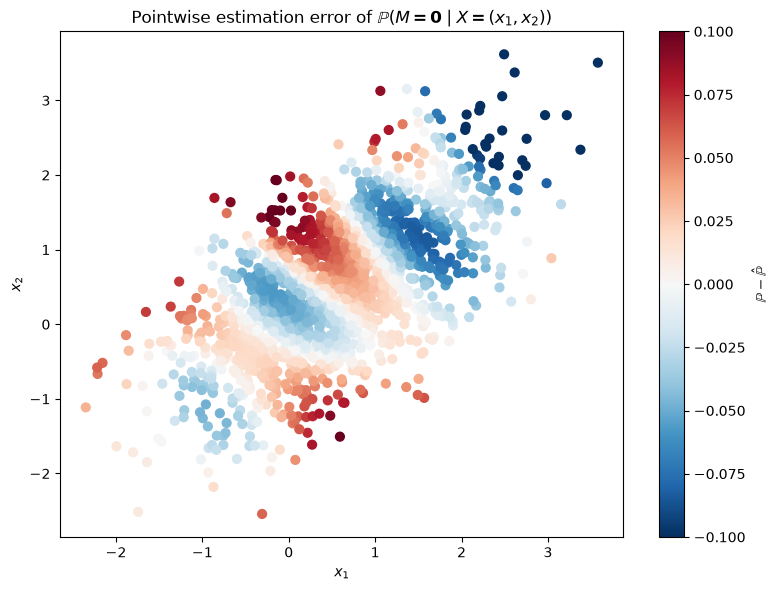

In [9]:
error = (Z - Zhat).detach().cpu().numpy()
limit = 0.1

fig, ax = plt.subplots(figsize=(8, 6))


sc = ax.scatter(
    X1p.detach().cpu().numpy() if isinstance(X1p, torch.Tensor) else X1p,
    X2p.detach().cpu().numpy() if isinstance(X2p, torch.Tensor) else X2p,
    c=error,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    s=40
)

fig.colorbar(sc, ax=ax, label=r"$\mathbb{P}-\hat \mathbb{P}$")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")

ax.set_title(r"Pointwise estimation error of $\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
plt.tight_layout()
plt.show()

# Compare by ratio to the truth

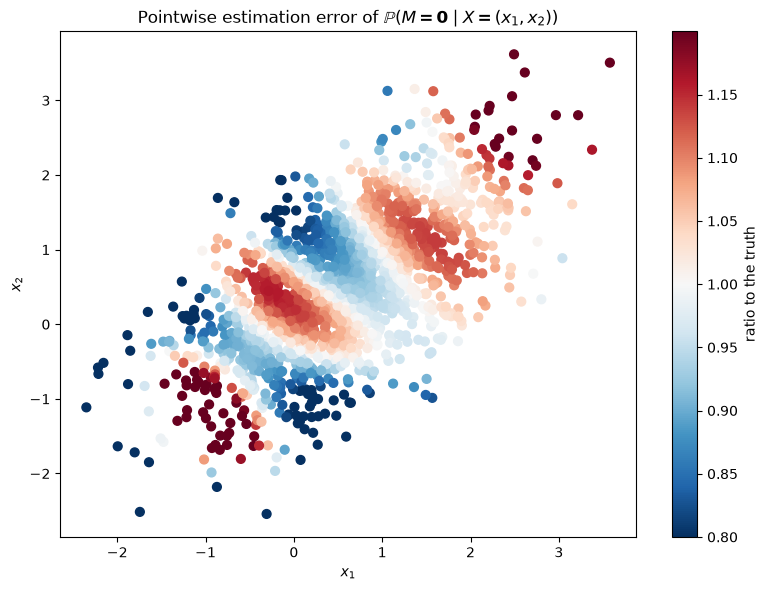

In [10]:
error = (Zhat / Z).detach().cpu().numpy()
limit = 0.2

fig, ax = plt.subplots(figsize=(8, 6))


sc = ax.scatter(
    X1p.detach().cpu().numpy() if isinstance(X1p, torch.Tensor) else X1p,
    X2p.detach().cpu().numpy() if isinstance(X2p, torch.Tensor) else X2p,
    c=error,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=1-limit, vcenter=1, vmax=1+limit),
    s=40
)

fig.colorbar(sc, ax=ax, label="ratio to the truth")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")

ax.set_title(r"Pointwise estimation error of $\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
plt.tight_layout()
plt.show()